In [40]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import yaml
import os

In [41]:
import torch
from deep_hedging.black_scholes import black_scholes_call_price

In [42]:
run_path = Path("../runs/cvar_nocost_seed0")

In [43]:
loss_path = os.path.join(run_path, "model_history.csv")
df = pl.read_csv(loss_path)
print(df)

shape: (2_000, 1)
┌──────────┐
│ loss     │
│ ---      │
│ f64      │
╞══════════╡
│ 5.050418 │
│ 5.02142  │
│ 5.455573 │
│ 5.191586 │
│ 5.129601 │
│ …        │
│ 2.659975 │
│ 2.663345 │
│ 2.677938 │
│ 2.655772 │
│ 2.688707 │
└──────────┘


In [44]:
df = df.with_columns(pl.col("loss").rolling_mean(window_size=100, min_samples=1).alias("loss_rolling_mean"))
df = df.with_row_index("iter")
print(df)

shape: (2_000, 3)
┌──────┬──────────┬───────────────────┐
│ iter ┆ loss     ┆ loss_rolling_mean │
│ ---  ┆ ---      ┆ ---               │
│ u32  ┆ f64      ┆ f64               │
╞══════╪══════════╪═══════════════════╡
│ 0    ┆ 5.050418 ┆ 5.050418          │
│ 1    ┆ 5.02142  ┆ 5.035919          │
│ 2    ┆ 5.455573 ┆ 5.175804          │
│ 3    ┆ 5.191586 ┆ 5.179749          │
│ 4    ┆ 5.129601 ┆ 5.16972           │
│ …    ┆ …        ┆ …                 │
│ 1995 ┆ 2.659975 ┆ 2.656287          │
│ 1996 ┆ 2.663345 ┆ 2.65655           │
│ 1997 ┆ 2.677938 ┆ 2.656468          │
│ 1998 ┆ 2.655772 ┆ 2.656137          │
│ 1999 ┆ 2.688707 ┆ 2.656326          │
└──────┴──────────┴───────────────────┘


In [45]:
config_path = os.path.join(run_path, "config.yaml")

In [46]:
with open(config_path) as f:
    config = yaml.safe_load(f)

S0 = config["market"]["S0"]
mu = config["market"]["mu"]
sigma = config["market"]["sigma"]
T = config["market"]["T"]
n_steps = config["market"]["n_steps"]
K = config["option"]["K"]

risk_measure = config["risk"]["name"]

bs_price = black_scholes_call_price(S=torch.tensor(S0, dtype=torch.float32), K=K, tau=torch.tensor(T, dtype=torch.float32), sigma=sigma).item()
print(bs_price)

2.2871475219726562


d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.api.interchange.from_dataframe(data)
d:\Perso_Projects\Perso_Projects\DeepHedging\.venv\Lib\site-packages\seaborn\_core\data.py:313: UserWarning: Conversion using Arrow PyCapsule Interface failed due to missing PyArrow>=14 dependency, falling back to (deprecated) interchange protocol. We recommend that you install PyArrow>=14.0.0.
  return pd.api.interchange.from_dataframe(data)


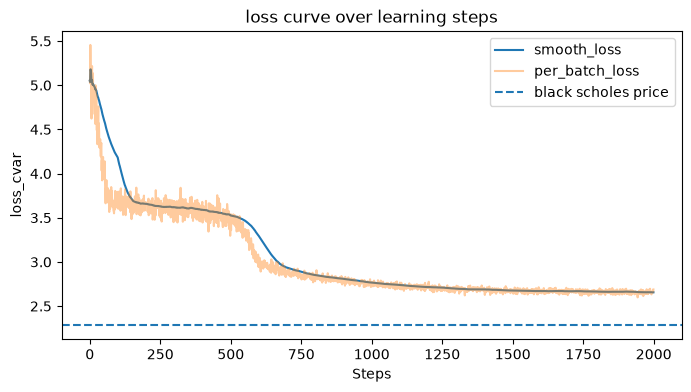

In [47]:
fig, ax = plt.subplots(figsize=(8,4))

sns.lineplot(data=df, x="iter", y="loss_rolling_mean", ax=ax, label="smooth_loss")
sns.lineplot(data=df, x="iter", y="loss", ax=ax, alpha=0.4, label="per_batch_loss")
ax.axhline(bs_price, linestyle="--", label="black scholes price")
ax.set_xlabel("Steps")
ax.set_ylabel(f"loss_{risk_measure}")
ax.set_title("loss curve over learning steps")
ax.legend()
fig.savefig("results/loss_curve/training_loss.png", dpi=150, bbox_inches="tight")
